# Homework 3: Noise and Linear Light
## Name: Jon Knapp
### Date: October 27, 2026
### Class: EE 513 Intro to Image Processing

## Part 1: Captures
### Problem 1: Capture at least ten pairs of flat fields spanning the range from nearly black to nearly saturated, two frames at each level with nothing moved or changed between them.
 _Deliverables: A contact sheet showing one frame from each pair, and a list giving the exposure time and ISO of every capture._

In [5]:
# If rawpy isn't installed:  %pip install rawpy
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
import tifffile
from matplotlib.patches import Rectangle

CAPTURE_ROOT = Path("Homework 3 Image Captures")
WHITE_DIR = CAPTURE_ROOT / "White Frames"
DARK_DIR = CAPTURE_ROOT / "Dark Frames"
PATCH = 128   # side of the central measurement patch, in green-plane pixels

In [6]:
def _lookup(page, name):
    """Find a tag in the EXIF sub-IFD, falling back to IFD0.
    iPhone raw apps put ISO/exposure in the EXIF IFD; Android's DngCreator
    (Open Camera) writes them into IFD0 directly."""
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    if name in exif:
        return exif[name]
    if name in page.tags:
        return page.tags[name].value
    return None


def iso_of(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings")
        if iso is None:
            iso = _lookup(p, "PhotographicSensitivity")
    if isinstance(iso, (tuple, list)):
        iso = iso[0]
    if iso is None:
        raise KeyError(f"No ISO field found in {Path(path).name}")
    return int(iso)


def exposure_of(path):
    """Exposure time in seconds, as a Fraction so the two frames of a pair group exactly."""
    with tifffile.TiffFile(path) as t:
        et = _lookup(t.pages[0], "ExposureTime")
    if et is None:
        raise KeyError(f"No ExposureTime field found in {Path(path).name}")
    if isinstance(et, (tuple, list)):
        return Fraction(int(et[0]), int(et[1]))
    return Fraction(et).limit_denominator(1_000_000)


def fmt_exposure(f):
    return f"{float(f):.3g} s" if f >= 1 else f"1/{1 / f:.4g} s"


def dng_files(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder.resolve()}")
    files = sorted(f for f in folder.iterdir() if f.suffix.lower() == ".dng")
    if not files:
        raise FileNotFoundError(f"No .dng files in {folder.resolve()}")
    return files

In [7]:
def green_plane(path):
    """Return (green plane in DN, black level of that plane, white level).
    Takes the first green site of the 2x2 Bayer tile, so it is one green
    channel, not a mix of G1 and G2."""
    with rawpy.imread(str(path)) as r:
        raw = r.raw_image_visible.astype(np.float64)   # copy before the file closes
        pattern = r.raw_pattern
        desc = r.color_desc.decode()
        gi, gj = next((i, j) for i in range(2) for j in range(2)
                      if desc[pattern[i, j]] == "G")
        black = float(r.black_level_per_channel[pattern[gi, gj]])
        white = float(r.white_level)
    return raw[gi::2, gj::2], black, white


def center_patch(plane, n=PATCH):
    h, w = plane.shape
    top, left = (h - n) // 2, (w - n) // 2
    return plane[top:top + n, left:left + n]

In [8]:
def capture_table(folder):
    rows = []
    for f in dng_files(folder):
        et = exposure_of(f)
        g, black, white = green_plane(f)
        m = center_patch(g).mean()
        rows.append({
            "file": f.name,
            "exposure": fmt_exposure(et),
            "exposure_s": float(et),
            "ISO": iso_of(f),
            "black_DN": black,
            "white_DN": white,
            "center_mean_DN": m,
            "pct_saturation": 100 * (m - black) / (white - black),
        })
    df = pd.DataFrame(rows).sort_values(["exposure_s", "file"]).reset_index(drop=True)
    df.insert(0, "pair", df.groupby("exposure_s", sort=True).ngroup() + 1)
    return df


white_df = capture_table(WHITE_DIR)
white_df.round({"exposure_s": 5, "center_mean_DN": 1, "pct_saturation": 1})

,pair,file,exposure,exposure_s,ISO,black_DN,white_DN,center_mean_DN,pct_saturation
0,1,IMG_0638.DNG,1/30 s,0.03333,50,528.0,4095.0,4079.4,99.6
1,1,IMG_0639.DNG,1/30 s,0.03333,50,528.0,4095.0,4079.5,99.6
2,2,IMG_0636.DNG,1/15 s,0.06667,50,528.0,4095.0,4079.4,99.6
3,2,IMG_0637.DNG,1/15 s,0.06667,50,528.0,4095.0,4079.4,99.6
4,3,IMG_0634.DNG,1/8 s,0.12500,50,528.0,4095.0,4079.4,99.6
5,3,IMG_0635.DNG,1/8 s,0.12500,50,528.0,4095.0,4079.4,99.6
6,4,IMG_0632.DNG,1/4 s,0.25000,50,528.0,4095.0,4079.4,99.6
7,4,IMG_0633.DNG,1/4 s,0.25000,50,528.0,4095.0,4079.4,99.6
8,5,IMG_0630.DNG,1/3 s,0.33333,50,528.0,4095.0,4080.1,99.6
9,5,IMG_0631.DNG,1/3 s,0.33333,50,528.0,4095.0,4080.1,99.6


In [9]:
counts = white_df.groupby("pair").size()
bad_pairs = counts[counts != 2]
short = white_df[white_df.exposure_s < 1 / 50]

print(f"{len(white_df)} flat-field frames, {white_df.pair.nunique()} exposure levels")
print(f"ISO value(s): {sorted(int(i) for i in white_df.ISO.unique())}")
print(f"Central-patch level spans {white_df.pct_saturation.min():.1f}% "
      f"to {white_df.pct_saturation.max():.1f}% of saturation")
if white_df.pair.nunique() < 10:
    print("! Fewer than 10 levels; the assignment asks for at least ten pairs.")
if len(bad_pairs):
    print("! Levels without exactly 2 frames:", dict(bad_pairs))
if len(short):
    print("! Exposures shorter than 1/50 s (screen flicker risk):",
          ", ".join(short.file))

14 flat-field frames, 7 exposure levels
ISO value(s): [50]
Central-patch level spans 99.6% to 99.6% of saturation
! Fewer than 10 levels; the assignment asks for at least ten pairs.


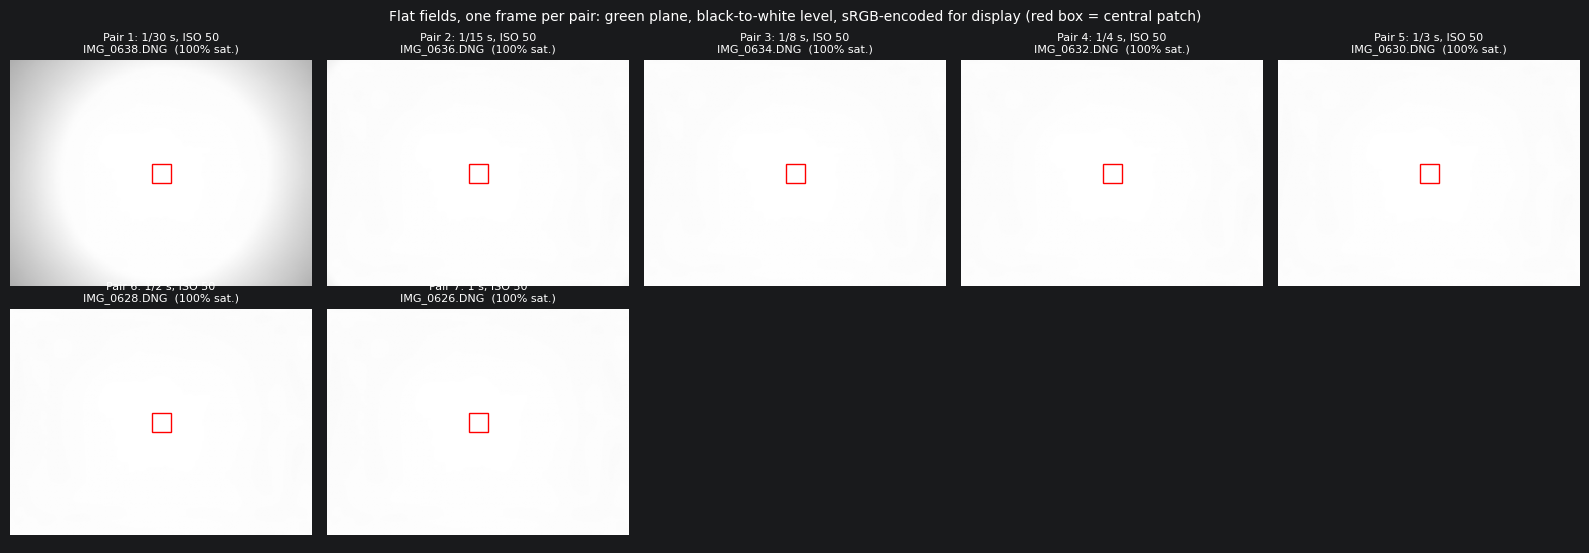

In [10]:
def srgb_encode(x):
    """Piecewise sRGB transfer function, linear [0, 1] -> encoded [0, 1]."""
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * np.power(x, 1 / 2.4) - 0.055)


def thumbnail(plane, black, white, factor=8):
    """Normalize to [0, 1] of the raw range, block-average in linear light, then encode."""
    x = (plane - black) / (white - black)
    h, w = (s // factor * factor for s in x.shape)
    x = x[:h, :w].reshape(h // factor, factor, w // factor, factor).mean(axis=(1, 3))
    return srgb_encode(x)


FACTOR = 8
reps = white_df.groupby("pair").first().reset_index()
ncols = 5
nrows = int(np.ceil(len(reps) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)

for ax, row in zip(axes.flat, reps.itertuples()):
    g, black, white = green_plane(WHITE_DIR / row.file)
    t = thumbnail(g, black, white, FACTOR)
    ax.imshow(t, cmap="gray", vmin=0, vmax=1)
    # outline the central patch used in Part 2
    s = PATCH / FACTOR
    ax.add_patch(Rectangle(((t.shape[1] - s) / 2, (t.shape[0] - s) / 2), s, s,
                           fill=False, edgecolor="red", linewidth=1))
    ax.set_title(f"Pair {row.pair}: {row.exposure}, ISO {row.ISO}\n"
                 f"{row.file}  ({row.pct_saturation:.0f}% sat.)", fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(reps):]:
    ax.axis("off")

fig.suptitle("Flat fields, one frame per pair: green plane, black-to-white level, "
             "sRGB-encoded for display (red box = central patch)", fontsize=10)
fig.tight_layout()
fig.savefig("hw3_item1_contact_sheet.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
white_df[["pair", "file", "exposure", "exposure_s", "ISO"]].style.hide(axis="index")

pair,file,exposure,exposure_s,ISO
1,IMG_0638.DNG,1/30 s,0.033333,50
1,IMG_0639.DNG,1/30 s,0.033333,50
2,IMG_0636.DNG,1/15 s,0.066667,50
2,IMG_0637.DNG,1/15 s,0.066667,50
3,IMG_0634.DNG,1/8 s,0.125000,50
3,IMG_0635.DNG,1/8 s,0.125000,50
4,IMG_0632.DNG,1/4 s,0.250000,50
4,IMG_0633.DNG,1/4 s,0.250000,50
5,IMG_0630.DNG,1/3 s,0.333333,50
5,IMG_0631.DNG,1/3 s,0.333333,50


### Problem 2: Confirm from the metadata that the entire series came from one camera at one ISO, using the lens_id helper from the Project 1 page together with the ISO field.
_Deliverable: The assertion passing, or an account of which captures differ and what you did about it._

In [4]:
"""
Homework 3 (Noise and Linear Light), Item 2:
Confirm from the metadata that every capture came from one camera at one ISO.

Run from the folder that contains "Homework 3 Image Captures":
    python hw3_item2_metadata_check.py

It prints a table of every DNG (lens, focal length, frame size, ISO, exposure),
groups the flat fields by exposure time so you can see the pairs, and asserts
that each series has exactly one camera and one ISO. The table doubles as the
"exposure time and ISO of every capture" list for item 1.
"""

from collections import defaultdict
from fractions import Fraction
from pathlib import Path

import tifffile

CAPTURE_ROOT = Path("Homework 3 Image Captures")
WHITE_DIR = CAPTURE_ROOT / "White Frames"
DARK_DIR = CAPTURE_ROOT / "Dark Frames"


# --- lens_id helper, as given on the Project 1 page --------------------------
def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


# --- ISO and exposure time ----------------------------------------------------
def _lookup(page, name):
    """Find a tag in the EXIF sub-IFD, falling back to IFD0.
    iPhone raw apps put ISO/exposure in the EXIF IFD; Android's DngCreator
    (Open Camera) writes them into IFD0 directly."""
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    if name in exif:
        return exif[name]
    if name in page.tags:
        return page.tags[name].value
    return None


def iso_of(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings")
        if iso is None:
            iso = _lookup(p, "PhotographicSensitivity")
    if isinstance(iso, (tuple, list)):
        iso = iso[0]
    if iso is None:
        raise KeyError(f"No ISO field found in {path.name}")
    return int(iso)


def exposure_of(path):
    """Exposure time in seconds, as a Fraction so pairs group exactly."""
    with tifffile.TiffFile(path) as t:
        et = _lookup(t.pages[0], "ExposureTime")
    if et is None:
        raise KeyError(f"No ExposureTime field found in {path.name}")
    if isinstance(et, (tuple, list)):
        return Fraction(int(et[0]), int(et[1]))
    return Fraction(et).limit_denominator(1_000_000)


def fmt_exposure(f):
    if f >= 1:
        return f"{float(f):.3g} s"
    return f"1/{1 / f:.4g} s"


# --- per-series check ---------------------------------------------------------
def dng_files(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder.resolve()}")
    files = sorted(f for f in folder.iterdir() if f.suffix.lower() == ".dng")
    if not files:
        raise FileNotFoundError(f"No .dng files in {folder.resolve()}")
    return files


def describe_series(name, files):
    rows = []
    for f in files:
        rows.append((f, lens_id(f), iso_of(f), exposure_of(f)))

    print(f"\n=== {name}: {len(files)} files ===")
    print(f"{'file':<28} {'ISO':>5} {'exposure':>12}  lens")
    for f, lid, iso, et in rows:
        print(f"{f.name:<28} {iso:>5} {fmt_exposure(et):>12}  {lid[0]}, "
              f"{lid[1]} mm, {lid[2]} mm equiv, {lid[3][0]}x{lid[3][1]}")

    lens_ids = {lid for _, lid, _, _ in rows}
    isos = {iso for _, _, iso, _ in rows}

    # If something differs, say which files, before the assert fires.
    for label, values, idx in (("camera", lens_ids, 1), ("ISO", isos, 2)):
        if len(values) > 1:
            print(f"\n  ! More than one {label} in {name}:")
            groups = defaultdict(list)
            for r in rows:
                groups[r[idx]].append(r[0].name)
            for v, names in groups.items():
                print(f"    {v}: {', '.join(names)}")

    return rows, lens_ids, isos


def print_pairs(rows):
    """Group flat fields by exposure time; each level should hold 2 frames."""
    by_exp = defaultdict(list)
    for f, _, _, et in rows:
        by_exp[et].append(f.name)
    print(f"\n  Flat-field levels ({len(by_exp)} exposure times):")
    for et in sorted(by_exp):
        names = by_exp[et]
        flag = "" if len(names) == 2 else f"   <-- {len(names)} frames, expected 2"
        print(f"    {fmt_exposure(et):>12}: {', '.join(names)}{flag}")
    short = [et for et in by_exp if et < Fraction(1, 50)]
    if short:
        print("  ! Exposures shorter than 1/50 s (screen flicker risk): "
              + ", ".join(fmt_exposure(e) for e in sorted(short)))


if __name__ == "__main__":
    white_rows, white_lens, white_iso = describe_series("White Frames",
                                                        dng_files(WHITE_DIR))
    print_pairs(white_rows)
    dark_rows, dark_lens, dark_iso = describe_series("Dark Frames",
                                                     dng_files(DARK_DIR))
    print_pairs(dark_rows)

    all_lens = white_lens | dark_lens
    all_iso = white_iso | dark_iso
    print("\nCamera(s):", all_lens)
    print("ISO(s):   ", all_iso)

    assert len(white_lens) == 1, f"more than one camera in white frames: {white_lens}"
    assert len(white_iso) == 1, f"more than one ISO in white frames: {white_iso}"
    assert len(dark_lens) == 1, f"more than one camera in dark frames: {dark_lens}"
    assert len(dark_iso) == 1, f"more than one ISO in dark frames: {dark_iso}"
    assert all_lens == white_lens, f"dark and white frames from different cameras: {all_lens}"
    assert all_iso == white_iso, f"dark and white frames at different ISOs: {all_iso}"
    print("\nPASS: all captures from one camera at one ISO.")


=== White Frames: 14 files ===
file                           ISO     exposure  lens
IMG_0626.DNG                    50          1 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0627.DNG                    50          1 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0628.DNG                    50        1/2 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0629.DNG                    50        1/2 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0630.DNG                    50        1/3 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0631.DNG                    50        1/3 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0632.DNG                    50        1/4 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0633.DNG      